In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Finance Data Analysis - Project 5")

Finance Data Analysis - Project 5


In [2]:
# Create simulated financial market data

np.random.seed(42)

n = 1500

dates = pd.date_range(
    start="2021-01-01",
    periods=n,
    freq="B"
)

daily_returns = np.random.normal(
    loc=0.0005,
    scale=0.02,
    size=n
)

starting_price = 100
close_prices = starting_price * np.cumprod(1 + daily_returns)

df = pd.DataFrame({
    "Date": dates,
    "Open": close_prices * np.random.uniform(0.98, 1.02, n),
    "High": close_prices * np.random.uniform(1.00, 1.04, n),
    "Low": close_prices * np.random.uniform(0.96, 1.00, n),
    "Close": close_prices,
    "Volume": np.random.randint(100000, 1000000, n)
})

df.head()

,Date,Open,High,Low,Close,Volume
0,2021-01-01,100.113104,101.968483,100.677847,101.043428,151990
1,2021-01-04,102.125324,103.221390,99.076314,100.814536,431065
2,2021-01-05,102.163743,105.964199,101.198919,102.170872,791898
3,2021-01-06,103.552135,109.248947,104.541216,105.334143,724860
4,2021-01-07,103.041317,106.328069,102.132092,104.893523,861269


In [3]:
# Create derived financial metrics

df["Daily_Return"] = df["Close"].pct_change() * 100

df["Price_Change"] = df["Close"] - df["Open"]

df["Daily_Range"] = df["High"] - df["Low"]

df["MA_20"] = df["Close"].rolling(window=20).mean()

df["MA_50"] = df["Close"].rolling(window=50).mean()

df["Volatility_20D"] = (
    df["Daily_Return"].rolling(window=20).std()
)

df.head()

,Date,Open,High,Low,Close,Volume,Daily_Return,Price_Change,Daily_Range,MA_20,MA_50,Volatility_20D
0,2021-01-01,100.113104,101.968483,100.677847,101.043428,151990,NaN,0.930324,1.290636,NaN,NaN,NaN
1,2021-01-04,102.125324,103.221390,99.076314,100.814536,431065,-0.226529,-1.310788,4.145076,NaN,NaN,NaN
2,2021-01-05,102.163743,105.964199,101.198919,102.170872,791898,1.345377,0.007129,4.765280,NaN,NaN,NaN
3,2021-01-06,103.552135,109.248947,104.541216,105.334143,724860,3.096060,1.782008,4.707732,NaN,NaN,NaN
4,2021-01-07,103.041317,106.328069,102.132092,104.893523,861269,-0.418307,1.852206,4.195977,NaN,NaN,NaN


In [4]:
# Convert Date to datetime format

df["Date"] = pd.to_datetime(df["Date"])

print("Date data type:", df["Date"].dtype)
print("Start Date:", df["Date"].min().date())
print("End Date:", df["Date"].max().date())

Date data type: datetime64[us]
Start Date: 2021-01-01
End Date: 2026-10-01


In [5]:
# Financial dataset validation

print("===== DATA VALIDATION =====")

print("\nDataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Dates:", df["Date"].nunique())

print("\nPrice Validation:")
print("Open minimum:", df["Open"].min())
print("High minimum:", df["High"].min())
print("Low minimum:", df["Low"].min())
print("Close minimum:", df["Close"].min())

print("\nVolume Range:")
print(df["Volume"].min(), "to", df["Volume"].max())

print("\nDate Range:")
print(df["Date"].min().date(), "to", df["Date"].max().date())

===== DATA VALIDATION =====

Dataset Shape: (1500, 12)

Missing Values:
Date               0
Open               0
High               0
Low                0
Close              0
Volume             0
Daily_Return       1
Price_Change       0
Daily_Range        0
MA_20             19
MA_50             49
Volatility_20D    20
dtype: int64

Duplicate Rows: 0

Unique Dates: 1500

Price Validation:
Open minimum: 78.47099234850336
High minimum: 79.45888986386657
Low minimum: 78.13141402997879
Close minimum: 79.04449139151174

Volume Range:
100037 to 999751

Date Range:
2021-01-01 to 2026-10-01


In [6]:
# Statistical summary of financial metrics

financial_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "Daily_Range"
]

financial_statistics = pd.DataFrame({
    "Mean": df[financial_columns].mean(),
    "Median": df[financial_columns].median(),
    "Minimum": df[financial_columns].min(),
    "Maximum": df[financial_columns].max()
})

financial_statistics.round(2)

,Mean,Median,Minimum,Maximum
Open,206.61,127.67,78.47,684.02
High,210.68,130.20,79.46,696.43
Low,202.50,125.22,78.13,674.74
Close,206.63,127.64,79.04,686.77
Volume,562108.98,574677.50,100037.00,999751.00
Daily_Return,0.15,0.15,-6.43,7.76
Daily_Range,8.18,5.55,0.25,42.32


In [7]:
ohlc_quality = pd.DataFrame({
    "High_below_Open": df["High"] < df["Open"],
    "High_below_Close": df["High"] < df["Close"],
    "Low_above_Open": df["Low"] > df["Open"],
    "Low_above_Close": df["Low"] > df["Close"]
})

ohlc_quality.sum()

High_below_Open     186
High_below_Close      0
Low_above_Open      183
Low_above_Close       0
dtype: int64

In [8]:
# Make High and Low consistent with Open and Close

df["High"] = df[["Open", "Close"]].max(axis=1) * np.random.uniform(1.00, 1.04, n)

df["Low"] = df[["Open", "Close"]].min(axis=1) * np.random.uniform(0.96, 1.00, n)

# Recalculate Daily Range
df["Daily_Range"] = df["High"] - df["Low"]

# Check again
ohlc_quality = pd.DataFrame({
    "High_below_Open": df["High"] < df["Open"],
    "High_below_Close": df["High"] < df["Close"],
    "Low_above_Open": df["Low"] > df["Open"],
    "Low_above_Close": df["Low"] > df["Close"]
})

ohlc_quality.sum()

High_below_Open     0
High_below_Close    0
Low_above_Open      0
Low_above_Close     0
dtype: int64

In [9]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.strftime("%b")

monthly_analysis = df.groupby(
    ["Year", "Month", "Month_Name"]
).agg(
    Average_Close=("Close", "mean"),
    Average_Return=("Daily_Return", "mean"),
    Total_Volume=("Volume", "sum"),
    Average_Volatility=("Volatility_20D", "mean")
).reset_index()

monthly_analysis.round(2).head(12)

,Year,Month,Month_Name,Average_Close,Average_Return,Total_Volume,Average_Volatility
0,2021,1,Jan,103.23,-0.20,11893168,2.04
1,2021,2,Feb,90.85,-0.55,12070966,1.85
2,2021,3,Mar,83.00,-0.32,15930918,1.78
3,2021,4,Apr,85.80,0.24,11464444,1.94
4,2021,5,May,83.84,-0.06,12069100,1.72
5,2021,6,Jun,85.17,0.32,11564454,1.94
6,2021,7,Jul,83.55,-0.30,13184351,2.08
7,2021,8,Aug,86.13,0.30,10804905,1.80
8,2021,9,Sep,94.52,0.29,11210733,1.91
9,2021,10,Oct,97.96,0.86,12517308,1.88


In [10]:
best_month = monthly_analysis.loc[
    monthly_analysis["Average_Return"].idxmax()
]

worst_month = monthly_analysis.loc[
    monthly_analysis["Average_Return"].idxmin()
]

print("Best Month by Average Return:")
print(best_month)

print("\nWorst Month by Average Return:")
print(worst_month)

Best Month by Average Return:
Year                        2026
Month                         10
Month_Name                   Oct
Average_Close         686.770783
Average_Return          1.235054
Total_Volume              758323
Average_Volatility      2.513231
Name: 69, dtype: object

Worst Month by Average Return:
Year                        2026
Month                          3
Month_Name                   Mar
Average_Close         371.841292
Average_Return         -0.832937
Total_Volume            11226631
Average_Volatility      2.167012
Name: 62, dtype: object


In [11]:
starting_price = df["Close"].iloc[0]
ending_price = df["Close"].iloc[-1]

overall_price_change = ending_price - starting_price
overall_return = ((ending_price / starting_price) - 1) * 100

print("Starting Price:", round(starting_price, 2))
print("Ending Price:", round(ending_price, 2))
print("Price Change:", round(overall_price_change, 2))
print("Overall Return:", round(overall_return, 2), "%")

Starting Price: 101.04
Ending Price: 686.77
Price Change: 585.73
Overall Return: 579.68 %


In [12]:
highest_volatility = df.loc[
    df["Volatility_20D"].idxmax()
]

lowest_volatility = df.loc[
    df["Volatility_20D"].idxmin()
]

print("Highest 20-Day Volatility:")
print(
    highest_volatility[
        ["Date", "Close", "Daily_Return", "Volatility_20D"]
    ]
)

print("\nLowest 20-Day Volatility:")
print(
    lowest_volatility[
        ["Date", "Close", "Daily_Return", "Volatility_20D"]
    ]
)

Highest 20-Day Volatility:
Date              2025-06-23 00:00:00
Close                      380.898862
Daily_Return                 2.818546
Volatility_20D               3.194393
Name: 1166, dtype: object

Lowest 20-Day Volatility:
Date              2022-03-28 00:00:00
Close                      121.159399
Daily_Return                 1.240314
Volatility_20D               1.099022
Name: 321, dtype: object


In [13]:
highest_volume = df.loc[
    df["Volume"].idxmax()
]

lowest_volume = df.loc[
    df["Volume"].idxmin()
]

print("Highest Trading Volume:")
print(
    highest_volume[
        ["Date", "Close", "Daily_Return", "Volume"]
    ]
)

print("\nLowest Trading Volume:")
print(
    lowest_volume[
        ["Date", "Close", "Daily_Return", "Volume"]
    ]
)

Highest Trading Volume:
Date            2023-12-18 00:00:00
Close                     108.04631
Daily_Return              -1.074934
Volume                       999751
Name: 771, dtype: object

Lowest Trading Volume:
Date            2026-07-28 00:00:00
Close                    532.233016
Daily_Return               0.531506
Volume                       100037
Name: 1452, dtype: object


In [14]:
correlation_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Daily_Return",
    "Daily_Range",
    "Volatility_20D"
]

finance_correlation = df[correlation_columns].corr()

finance_correlation.round(3)

,Open,High,Low,Close,Volume,Daily_Return,Daily_Range,Volatility_20D
Open,1.000,1.000,1.000,1.000,0.026,0.063,0.839,0.057
High,1.000,1.000,1.000,1.000,0.027,0.063,0.847,0.056
Low,1.000,1.000,1.000,1.000,0.027,0.063,0.831,0.056
Close,1.000,1.000,1.000,1.000,0.026,0.063,0.839,0.057
Volume,0.026,0.027,0.027,0.026,1.000,0.045,0.020,-0.041
Daily_Return,0.063,0.063,0.063,0.063,0.045,1.000,0.054,0.004
Daily_Range,0.839,0.847,0.831,0.839,0.020,0.054,1.000,0.049
Volatility_20D,0.057,0.056,0.056,0.057,-0.041,0.004,0.049,1.000


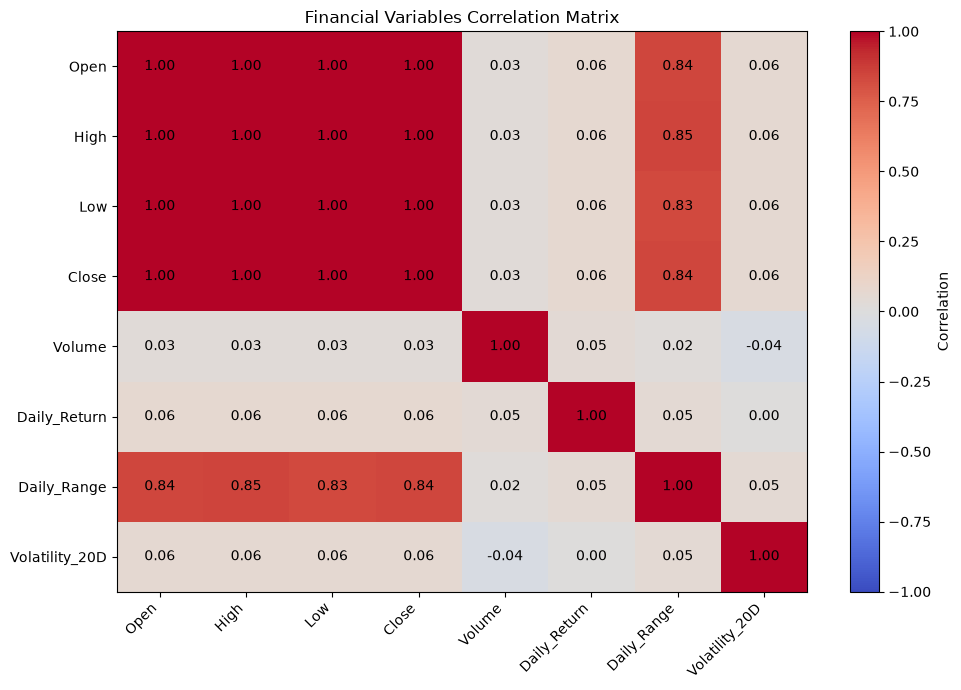

In [15]:
plt.figure(figsize=(10, 7))

plt.imshow(
    finance_correlation,
    cmap="coolwarm",
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(finance_correlation.columns)),
    finance_correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(finance_correlation.index)),
    finance_correlation.index
)

for i in range(len(finance_correlation.index)):
    for j in range(len(finance_correlation.columns)):
        plt.text(
            j,
            i,
            f"{finance_correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Financial Variables Correlation Matrix")
plt.tight_layout()

plt.savefig(
    "finance_correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

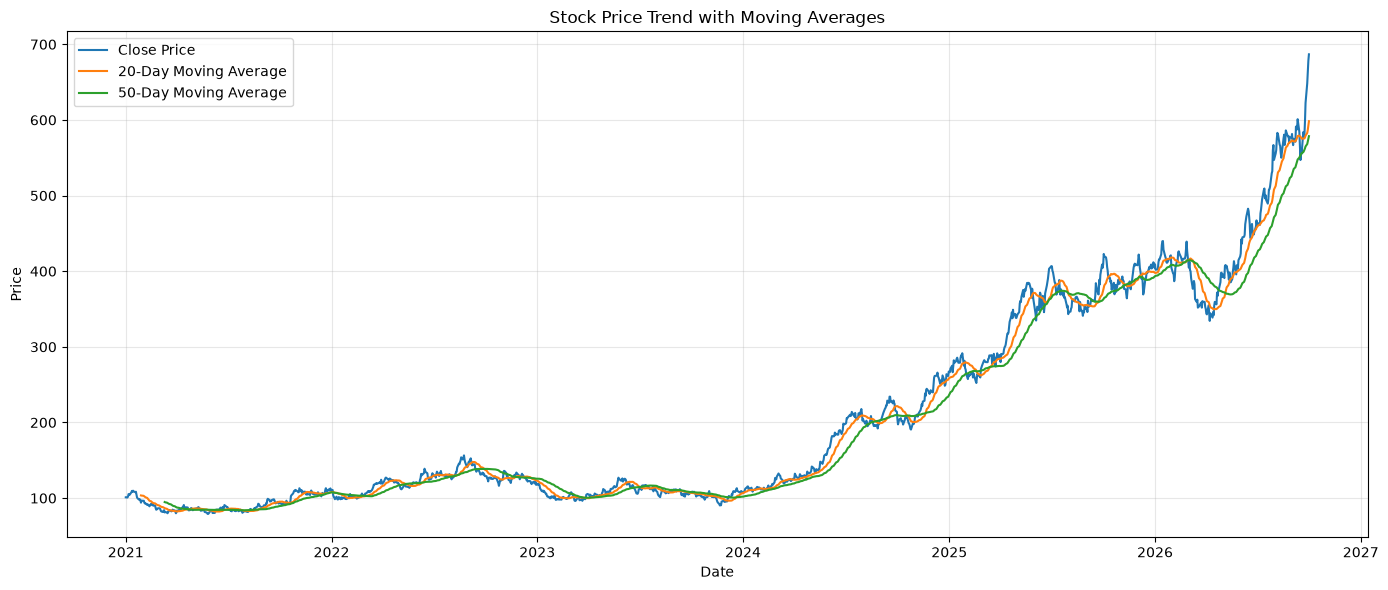

In [16]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Close"],
    label="Close Price"
)

plt.plot(
    df["Date"],
    df["MA_20"],
    label="20-Day Moving Average"
)

plt.plot(
    df["Date"],
    df["MA_50"],
    label="50-Day Moving Average"
)

plt.title("Stock Price Trend with Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "finance_price_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

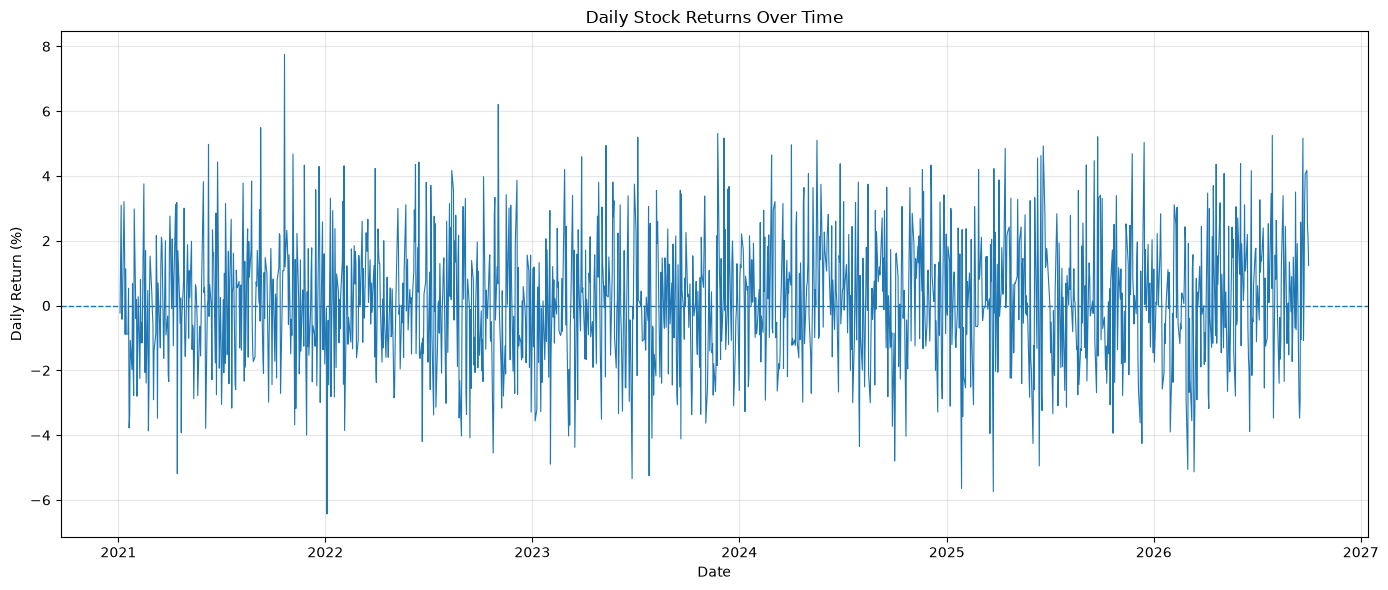

In [17]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Daily_Return"],
    linewidth=0.8
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Daily Stock Returns Over Time")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "finance_daily_returns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

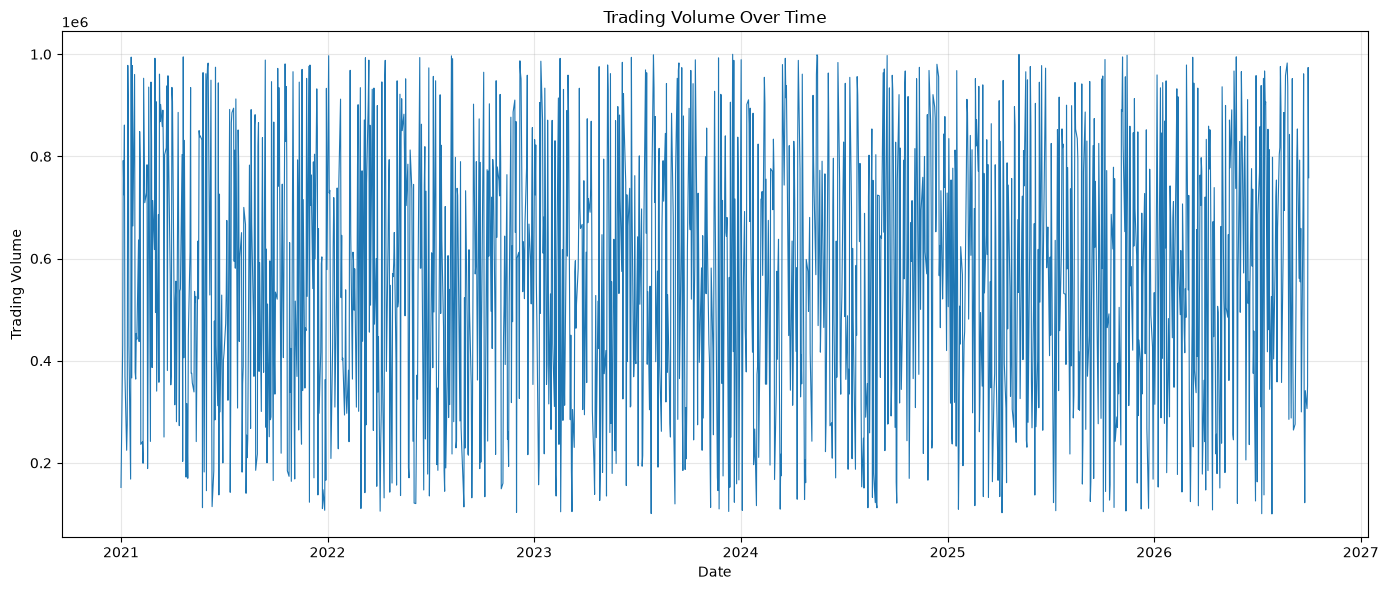

In [18]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Volume"],
    linewidth=0.8
)

plt.title("Trading Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Trading Volume")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "finance_trading_volume.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

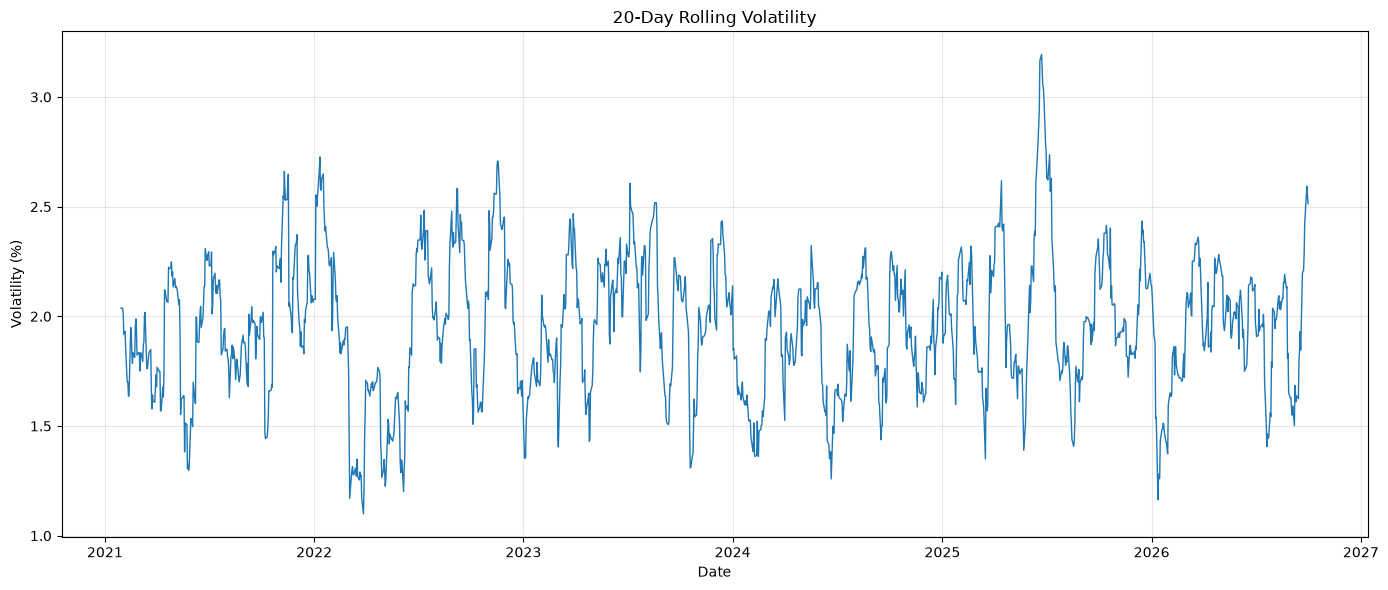

In [22]:
plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["Volatility_20D"],
    linewidth=1
)

plt.title("20-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility (%)")
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "finance_volatility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
monthly_return_summary = (
    df.groupby("Month_Name")["Daily_Return"]
    .mean()
    .reindex([
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ])
)

print("Average Daily Return by Calendar Month:")
print(monthly_return_summary.round(3))

Average Daily Return by Calendar Month:
Month_Name
Jan   -0.188
Feb    0.141
Mar   -0.018
Apr    0.350
May    0.335
Jun    0.378
Jul   -0.030
Aug    0.202
Sep    0.237
Oct    0.019
Nov    0.172
Dec    0.169
Name: Daily_Return, dtype: float64


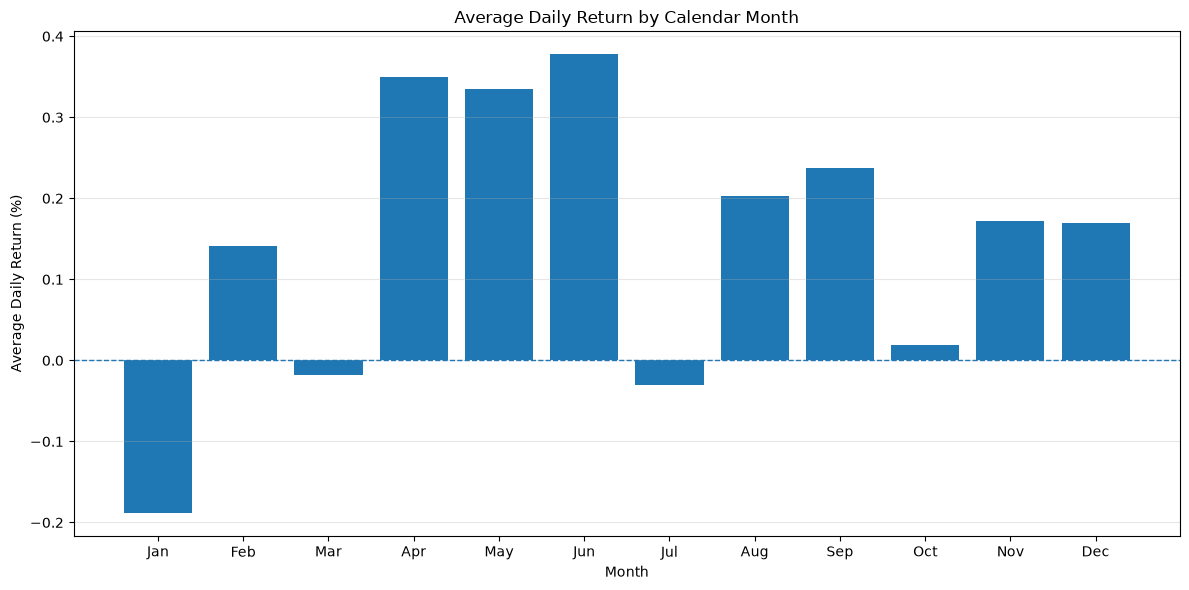

In [24]:
plt.figure(figsize=(12, 6))

plt.bar(
    monthly_return_summary.index,
    monthly_return_summary.values
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title("Average Daily Return by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Return (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "finance_monthly_returns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
df["MA_Signal"] = np.where(
    df["MA_20"] > df["MA_50"],
    "Bullish",
    "Bearish"
)

signal_summary = df["MA_Signal"].value_counts()

print("Moving Average Signal Summary:")
print(signal_summary)

print("\nSignal Percentage:")
print(
    (signal_summary / signal_summary.sum() * 100).round(2)
)

Moving Average Signal Summary:
MA_Signal
Bullish    923
Bearish    577
Name: count, dtype: int64

Signal Percentage:
MA_Signal
Bullish    61.53
Bearish    38.47
Name: count, dtype: float64


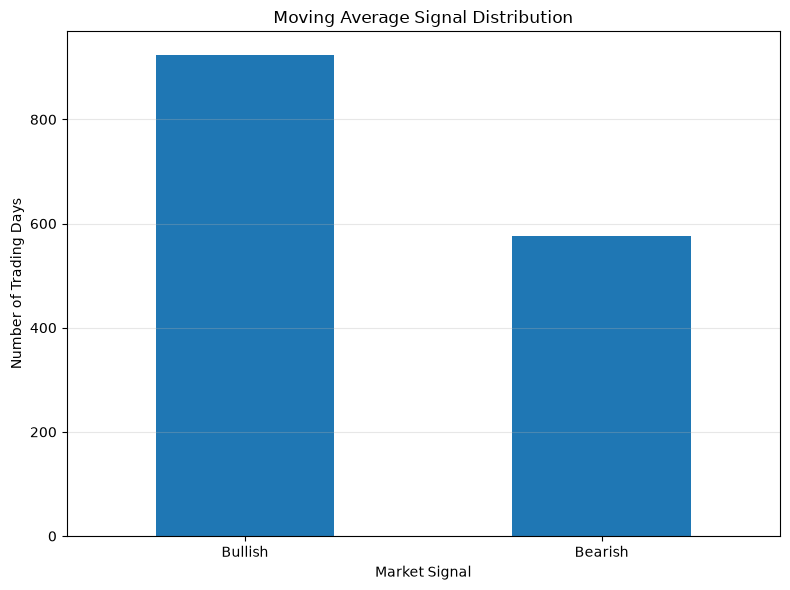

In [26]:
plt.figure(figsize=(8, 6))

signal_summary.plot(
    kind="bar"
)

plt.title("Moving Average Signal Distribution")
plt.xlabel("Market Signal")
plt.ylabel("Number of Trading Days")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "finance_ma_signals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
positive_days = (df["Daily_Return"] > 0).sum()
negative_days = (df["Daily_Return"] < 0).sum()

risk_summary = {
    "Average Daily Return (%)": df["Daily_Return"].mean(),
    "Daily Return Volatility (%)": df["Daily_Return"].std(),
    "Best Daily Return (%)": df["Daily_Return"].max(),
    "Worst Daily Return (%)": df["Daily_Return"].min(),
    "Positive Return Days (%)": (positive_days / len(df)) * 100,
    "Negative Return Days (%)": (negative_days / len(df)) * 100
}

pd.Series(risk_summary).round(2)

Average Daily Return (%)        0.15
Daily Return Volatility (%)     1.98
Best Daily Return (%)           7.76
Worst Daily Return (%)         -6.43
Positive Return Days (%)       53.13
Negative Return Days (%)       46.80
dtype: float64

In [29]:
finance_kpi_summary = pd.DataFrame({
    "Metric": [
        "Starting Price",
        "Ending Price",
        "Overall Return (%)",
        "Average Daily Return (%)",
        "Daily Volatility (%)",
        "Best Daily Return (%)",
        "Worst Daily Return (%)",
        "Positive Return Days (%)",
        "Negative Return Days (%)",
        "Bullish MA Days (%)",
        "Bearish MA Days (%)"
    ],
    "Value": [
        starting_price,
        ending_price,
        overall_return,
        df["Daily_Return"].mean(),
        df["Daily_Return"].std(),
        df["Daily_Return"].max(),
        df["Daily_Return"].min(),
        (positive_days / len(df)) * 100,
        (negative_days / len(df)) * 100,
        (signal_summary["Bullish"] / len(df)) * 100,
        (signal_summary["Bearish"] / len(df)) * 100
    ]
})

finance_kpi_summary["Value"] = finance_kpi_summary["Value"].round(2)

finance_kpi_summary

,Metric,Value
0,Starting Price,101.04
1,Ending Price,686.77
2,Overall Return (%),579.68
3,Average Daily Return (%),0.15
4,Daily Volatility (%),1.98
5,Best Daily Return (%),7.76
6,Worst Daily Return (%),-6.43
7,Positive Return Days (%),53.13
8,Negative Return Days (%),46.80
9,Bullish MA Days (%),61.53


In [30]:
df.to_csv(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\data\finance_data.csv",
    index=False
)

print("Finance dataset saved successfully.")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Finance dataset saved successfully.
Rows: 1500
Columns: 16


In [31]:
print("===== FINAL FINANCE DATA VALIDATION =====")

print("Dataset Shape:", df.shape)
print("Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("Unique Dates:", df["Date"].nunique())

print("\nOHLC Validation:")
print("High >= Open:", (df["High"] >= df["Open"]).all())
print("High >= Close:", (df["High"] >= df["Close"]).all())
print("Low <= Open:", (df["Low"] <= df["Open"]).all())
print("Low <= Close:", (df["Low"] <= df["Close"]).all())

print("\nPrice Validation:")
print("All Prices Positive:", (
    (df[["Open", "High", "Low", "Close"]] > 0).all().all()
))

print("\nVolume Validation:")
print("All Volumes Positive:", (df["Volume"] > 0).all())

print("\nDate Range:")
print(df["Date"].min().date(), "to", df["Date"].max().date())

===== FINAL FINANCE DATA VALIDATION =====
Dataset Shape: (1500, 16)
Missing Values: 89
Duplicate Rows: 0
Unique Dates: 1500

OHLC Validation:
High >= Open: True
High >= Close: True
Low <= Open: True
Low <= Close: True

Price Validation:
All Prices Positive: True

Volume Validation:
All Volumes Positive: True

Date Range:
2021-01-01 to 2026-10-01


In [32]:
missing_values = df.isna().sum()

print("Missing Values by Column:")
print(missing_values[missing_values > 0])

Missing Values by Column:
Daily_Return       1
MA_20             19
MA_50             49
Volatility_20D    20
dtype: int64


In [33]:
df_analysis = df.dropna(
    subset=[
        "Daily_Return",
        "MA_20",
        "MA_50",
        "Volatility_20D"
    ]
).copy()

print("Original Dataset:", df.shape)
print("Clean Analysis Dataset:", df_analysis.shape)
print("Missing Values:", df_analysis.isna().sum().sum())

Original Dataset: (1500, 16)
Clean Analysis Dataset: (1451, 16)
Missing Values: 0


In [34]:
final_statistics = pd.DataFrame({
    "Mean": df_analysis[
        ["Open", "High", "Low", "Close", "Volume",
         "Daily_Return", "Daily_Range", "Volatility_20D"]
    ].mean(),
    "Median": df_analysis[
        ["Open", "High", "Low", "Close", "Volume",
         "Daily_Return", "Daily_Range", "Volatility_20D"]
    ].median(),
    "Minimum": df_analysis[
        ["Open", "High", "Low", "Close", "Volume",
         "Daily_Return", "Daily_Range", "Volatility_20D"]
    ].min(),
    "Maximum": df_analysis[
        ["Open", "High", "Low", "Close", "Volume",
         "Daily_Return", "Daily_Range", "Volatility_20D"]
    ].max()
})

final_statistics.round(2)

,Mean,Median,Minimum,Maximum
Open,210.38,129.42,78.47,684.02
High,215.70,132.66,79.49,707.45
Low,205.26,126.10,75.80,675.89
Close,210.39,129.37,79.04,686.77
Volume,560884.42,574081.00,100037.00,999751.00
Daily_Return,0.16,0.17,-6.43,7.76
Daily_Range,10.43,7.27,0.62,46.86
Volatility_20D,1.95,1.95,1.10,3.19


In [35]:
best_month = monthly_analysis.loc[
    monthly_analysis["Average_Return"].idxmax()
]

worst_month = monthly_analysis.loc[
    monthly_analysis["Average_Return"].idxmin()
]

highest_volatility = df_analysis.loc[
    df_analysis["Volatility_20D"].idxmax()
]

highest_volume = df.loc[
    df["Volume"].idxmax()
]

print("===== FINANCE PROJECT KEY INSIGHTS =====")

print(
    f"1. Overall price increased from "
    f"{starting_price:.2f} to {ending_price:.2f}, "
    f"representing an overall return of {overall_return:.2f}%."
)

print(
    f"2. Best monthly average return: "
    f"{best_month['Month_Name']} {int(best_month['Year'])} "
    f"({best_month['Average_Return']:.2f}%)."
)

print(
    f"3. Worst monthly average return: "
    f"{worst_month['Month_Name']} {int(worst_month['Year'])} "
    f"({worst_month['Average_Return']:.2f}%)."
)

print(
    f"4. Average daily return was "
    f"{df_analysis['Daily_Return'].mean():.2f}% "
    f"with daily volatility of "
    f"{df_analysis['Daily_Return'].std():.2f}%."
)

print(
    f"5. Best daily return was "
    f"{df_analysis['Daily_Return'].max():.2f}% "
    f"and worst daily return was "
    f"{df_analysis['Daily_Return'].min():.2f}%."
)

print(
    f"6. The 20-day volatility reached a maximum of "
    f"{highest_volatility['Volatility_20D']:.2f}% "
    f"on {highest_volatility['Date'].date()}."
)

print(
    f"7. Bullish moving-average conditions occurred on "
    f"{signal_summary['Bullish'] / len(df) * 100:.2f}% "
    f"of trading days."
)

print(
    f"8. Highest trading volume was "
    f"{int(highest_volume['Volume']):,} "
    f"on {highest_volume['Date'].date()}."
)

===== FINANCE PROJECT KEY INSIGHTS =====
1. Overall price increased from 101.04 to 686.77, representing an overall return of 579.68%.
2. Best monthly average return: Oct 2026 (1.24%).
3. Worst monthly average return: Mar 2026 (-0.83%).
4. Average daily return was 0.16% with daily volatility of 1.98%.
5. Best daily return was 7.76% and worst daily return was -6.43%.
6. The 20-day volatility reached a maximum of 3.19% on 2025-06-23.
7. Bullish moving-average conditions occurred on 61.53% of trading days.
8. Highest trading volume was 999,751 on 2023-12-18.


# Executive Summary

This Finance Data Analysis project examines simulated daily financial market data covering 1,500 business days from January 2021 to October 2026. The analysis focuses on price trends, daily returns, trading volume, volatility, moving averages, and risk indicators.

## Key Findings

- The simulated asset price increased from **101.04** to **686.77**, representing an overall price return of **579.68%** over the analysis period.
- The average daily return was **0.16%**, while daily return volatility was **1.98%**.
- The best daily return was **7.76%**, while the worst daily return was **-6.43%**.
- **June** recorded the highest average daily return among calendar months at **0.378%**.
- **January** recorded the lowest average daily return at **-0.188%**.
- The maximum 20-day rolling volatility was **3.19%**, observed on **June 23, 2025**.
- Bullish moving-average conditions occurred on approximately **61.53%** of trading days.
- The highest recorded trading volume was **999,751** on **December 18, 2023**.

## Business and Analytical Implications

The analysis demonstrates how financial data can be evaluated using trend analysis, moving averages, return distributions, volatility measurements, correlation analysis, and trading-volume analysis. These techniques can help analysts identify periods of stronger or weaker performance and understand changes in market activity and risk.

Because the dataset is simulated, the results should be treated as an analytical demonstration rather than real investment performance or financial advice.

# Insights & Recommendations

## Key Insights

### 1. Strong Overall Price Growth
The simulated asset increased from **101.04** to **686.77**, producing an overall price return of **579.68%** during the analysis period.

### 2. Daily Return and Risk
The average daily return was **0.16%**, with daily return volatility of **1.98%**. Daily returns ranged from **-6.43% to +7.76%**, indicating that significant short-term price movements occurred in the simulated dataset.

### 3. Monthly Performance
June had the highest average daily return among calendar months at **0.378%**, while January had the lowest at **-0.188%**. These patterns are descriptive and should not be interpreted as reliable seasonal investment effects.

### 4. Volatility
The highest 20-day rolling volatility was **3.19% on June 23, 2025**. Monitoring rolling volatility can help identify periods with increased price uncertainty.

### 5. Trading Activity
The highest trading volume was **999,751 on December 18, 2023**, when the daily return was **-1.07%**. However, the correlation between volume and daily return was only **0.045**, indicating almost no linear relationship in this simulated dataset.

### 6. Moving Average Signals
The 20-day moving average was above the 50-day moving average on **61.53%** of trading days, compared with **38.47%** of days with a bearish moving-average relationship.

## Recommendations

1. **Monitor price trends:** Use moving averages alongside price charts to understand changes in short- and medium-term trends.

2. **Track volatility:** Monitor rolling volatility to identify periods of increased market uncertainty and potential risk.

3. **Evaluate returns carefully:** Consider both average returns and the range of positive and negative daily returns rather than relying only on overall performance.

4. **Monitor trading volume:** Track unusual volume activity together with price movements to identify periods that may require additional investigation.

5. **Use multiple indicators:** Combine price trends, returns, volatility, volume, and moving averages instead of relying on a single metric.

6. **Validate with real data:** For practical financial analysis, replace the simulated dataset with reliable market data and apply appropriate financial and statistical validation.

> **Important:** This project uses simulated financial data for educational and portfolio purposes. The findings are not investment recommendations or financial advice.

# Data Dictionary

| Column | Description |
|---|---|
| `Date` | Trading/business date |
| `Open` | Simulated opening price |
| `High` | Simulated highest price during the trading day |
| `Low` | Simulated lowest price during the trading day |
| `Close` | Simulated closing price |
| `Volume` | Simulated number of traded units |
| `Daily_Return` | Percentage change in closing price from the previous trading day |
| `Price_Change` | Difference between closing price and opening price |
| `Daily_Range` | Difference between the daily high and low prices |
| `MA_20` | 20-day moving average of the closing price |
| `MA_50` | 50-day moving average of the closing price |
| `Volatility_20D` | Rolling 20-day standard deviation of daily returns |
| `Year` | Year extracted from the trading date |
| `Month` | Numeric month extracted from the trading date |
| `Month_Name` | Three-letter month name |
| `MA_Signal` | Bullish when MA_20 is above MA_50; otherwise Bearish |

# Data Quality & Validation

The finance dataset was validated before final analysis.

### Validation Results

- **Dataset size:** 1,500 rows × 16 columns
- **Duplicate rows:** 0
- **Unique trading dates:** 1,500
- **Missing values in original dataset:** 89
- The 89 missing values occur only in calculated rolling metrics during their initial observation windows.
- A separate clean analysis dataset was created with **1,451 rows** and **0 missing values**.
- **High ≥ Open:** True
- **High ≥ Close:** True
- **Low ≤ Open:** True
- **Low ≤ Close:** True
- **All prices positive:** True
- **All trading volumes positive:** True
- **Date range:** January 1, 2021 – October 1, 2026

The missing values in the initial rolling calculations were retained rather than artificially replacing them with zeros. Rows affected by incomplete rolling windows were excluded only when producing statistics that required complete calculated metrics.

The OHLC consistency checks confirmed that the simulated price data follows standard logical relationships between opening, high, low, and closing prices.

> **Dataset note:** This project uses simulated financial market data created for educational and portfolio analysis. It does not represent actual market prices or investment performance.